# 实验二 图像增强

**实验目的**：掌握 OpenCV 图像读取与色彩空间转换，学会添加椒盐噪声 / 高斯噪声，并用均值、中值、高斯滤波完成图像增强；最后手动实现彩色图像的中值滤波。

> 运行前请把实验用的图片命名为 `p1.jpg` 放在本 Notebook 同一目录下。若没有图片，程序会自动生成一张示例图，方便先把流程跑通。


In [1]:
import os
import glob

import cv2
import numpy as np
from skimage.util import random_noise
import skimage
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

print('OpenCV      :', cv2.__version__)
print('NumPy       :', np.__version__)
print('scikit-image:', skimage.__version__)
print('Matplotlib  :', plt.matplotlib.__version__)

RESULT_DIR = 'result'
os.makedirs(RESULT_DIR, exist_ok=True)
print('结果保存目录:', os.path.abspath(RESULT_DIR))


OpenCV      : 5.0.0
NumPy       : 2.0.1
scikit-image: 0.26.0
Matplotlib  : 3.11.2
结果保存目录: D:\dsh工作区\2nd.exp\result


## 1. 读取原始图像并查看像素值

`cv2.imread` 默认按 **BGR** 顺序读入；这里同时打印 `[100,100]` 像素的 BGR 值，用来验证通道顺序。


In [2]:
def locate_image():
    """优先找 p1.jpg / p1.png；否则用目录下第一张图；都没有则生成示例图。"""
    for name in ('p1.jpg', 'p1.jpeg', 'p1.png'):
        if os.path.exists(name):
            return name
    candidates = sorted(
        f for f in glob.glob('*')
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
    )
    if candidates:
        return candidates[0]

    # 没有图片时生成一张示例图（彩色渐变 + 几何图形），只为跑通流程
    h, w = 600, 800
    demo = np.zeros((h, w, 3), np.uint8)
    demo[:, :, 0] = np.linspace(0, 255, w, dtype=np.uint8)[None, :]
    demo[:, :, 1] = np.linspace(0, 255, h, dtype=np.uint8)[:, None]
    demo[:, :, 2] = 120
    cv2.circle(demo, (w // 2, h // 2), 150, (60, 60, 220), -1)
    cv2.rectangle(demo, (40, 40), (240, 180), (60, 200, 60), -1)
    cv2.imwrite('p1_demo.jpg', demo)
    print('未找到 p1.jpg，已生成示例图 p1_demo.jpg；正式实验请换成自己的照片后重新运行。')
    return 'p1_demo.jpg'


IMG_PATH = locate_image()
img = cv2.imread(IMG_PATH)
assert img is not None, f'无法读取图像：{IMG_PATH}'

print('使用图片 :', IMG_PATH)
print('图像尺寸 :', img.shape, '(高, 宽, 通道)')

y0 = min(100, img.shape[0] - 1)
x0 = min(100, img.shape[1] - 1)
b, g, r = img[y0, x0]
print(f'像素 [{y0},{x0}] 的 BGR = ({b}, {g}, {r})，对应 RGB = ({r}, {g}, {b})')


使用图片 : p1.jpg
图像尺寸 : (7728, 5152, 3) (高, 宽, 通道)
像素 [100,100] 的 BGR = (203, 162, 117)，对应 RGB = (117, 162, 203)


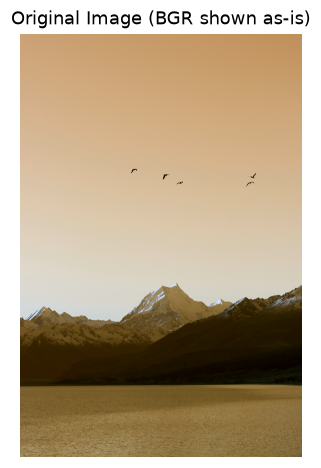

In [3]:
plt.figure(figsize=(6, 5))
plt.imshow(img)          # BGR 图直接交给 matplotlib 显示，红蓝会互换
plt.title('Original Image (BGR shown as-is)')
plt.axis('off')
plt.savefig(f'{RESULT_DIR}/original_bgr.jpg', dpi=300, bbox_inches='tight')
plt.show()


## 2. BGR → RGB 色彩空间转换

Matplotlib 按 RGB 显示，所以要把 B、R 两个通道交换，颜色才正常。


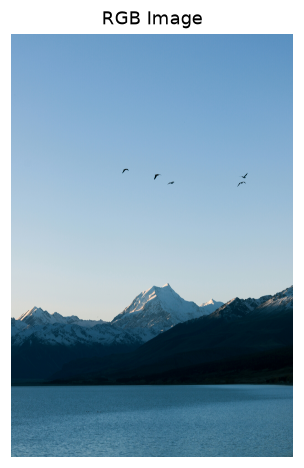

In [4]:
rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 5))
plt.imshow(rgb_img)
plt.title('RGB Image')
plt.axis('off')
plt.savefig(f'{RESULT_DIR}/rgb_image.jpg', dpi=300, bbox_inches='tight')
plt.show()


## 3. 转换为灰度图

灰度图把三维的 RGB 通道压缩为一维亮度通道，后续滤波处理更直观。


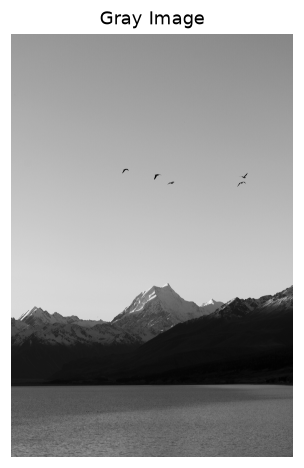

灰度图形状: (7728, 5152)
灰度范围  : 0 ~ 253


In [5]:
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 5))
plt.imshow(gray_img, cmap='gray')
plt.title('Gray Image')
plt.axis('off')
plt.savefig(f'{RESULT_DIR}/gray_image.jpg', dpi=300, bbox_inches='tight')
plt.show()

print('灰度图形状:', gray_img.shape)
print('灰度范围  :', gray_img.min(), '~', gray_img.max())


## 4. 添加噪声

- 椒盐噪声：`amount=0.4` 表示约 40% 的像素被随机置为黑 / 白点；
- 高斯噪声：每个像素叠加均值 0.2、方差 0.03 的高斯随机偏差。

`skimage` 的 `random_noise` 返回 `float64`，取值范围 [0, 1]。


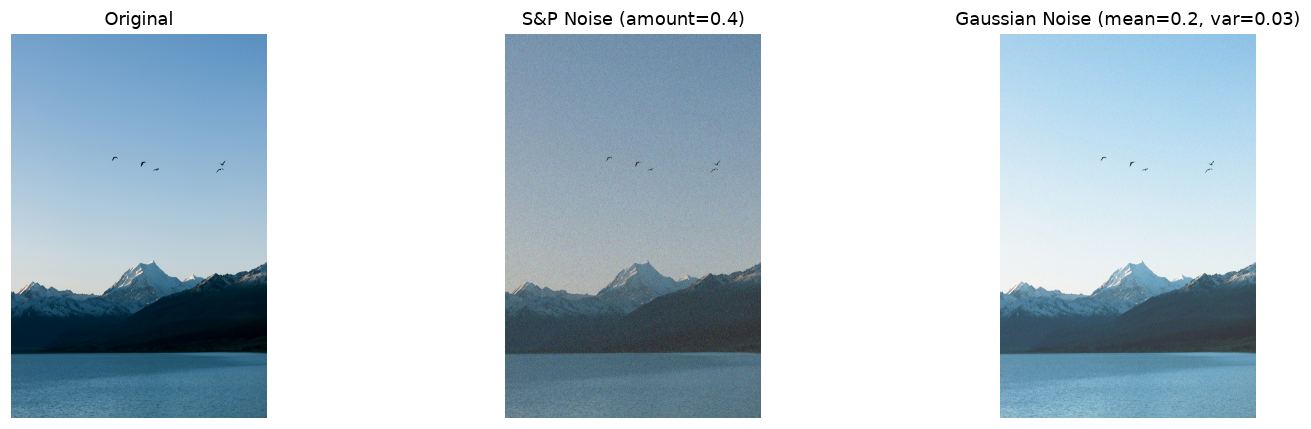

椒盐噪声 dtype: float64  范围: 0.0 ~ 1.0
高斯噪声 dtype: float64  范围: 0.0 ~ 1.0


In [6]:
sp_noise_img = random_noise(rgb_img, mode='s&p', amount=0.4)
gus_noise_img = random_noise(rgb_img, mode='gaussian', mean=0.2, var=0.03)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(rgb_img)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(sp_noise_img)
plt.title('S&P Noise (amount=0.4)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(gus_noise_img)
plt.title('Gaussian Noise (mean=0.2, var=0.03)')
plt.axis('off')

plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/noise_comparison.jpg', dpi=300, bbox_inches='tight')
plt.show()

print('椒盐噪声 dtype:', sp_noise_img.dtype, ' 范围:', sp_noise_img.min(), '~', sp_noise_img.max())
print('高斯噪声 dtype:', gus_noise_img.dtype, ' 范围:', gus_noise_img.min(), '~', gus_noise_img.max())


## 5. 三种滤波方法对比

滤波前先转成 `uint8`（`medianBlur` 要求 8 位图像），然后分别对椒盐噪声图和高斯噪声图做均值、中值、高斯滤波。


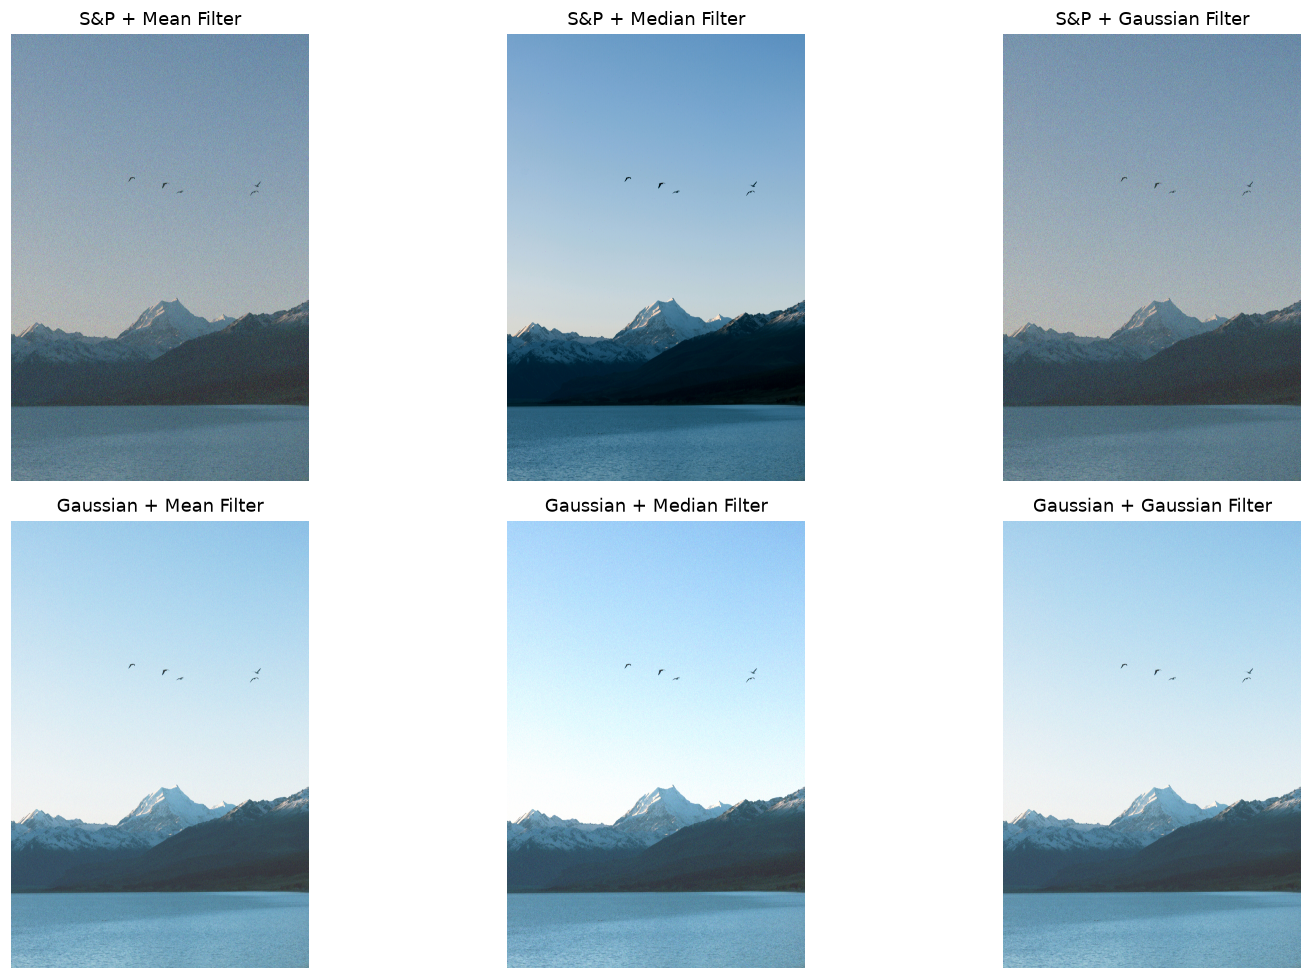

In [7]:
sp_u8 = (sp_noise_img * 255).astype(np.uint8)
gus_u8 = (gus_noise_img * 255).astype(np.uint8)

# 均值滤波
mean_sp = cv2.blur(sp_u8, (5, 5))
mean_gus = cv2.blur(gus_u8, (5, 5))

# 中值滤波（需要 uint8）
mid_sp = cv2.medianBlur(sp_u8, 5)
mid_gus = cv2.medianBlur(gus_u8, 5)

# 高斯滤波
gauss_sp = cv2.GaussianBlur(sp_u8, (5, 5), 0)
gauss_gus = cv2.GaussianBlur(gus_u8, (5, 5), 0)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
titles = [
    ['S&P + Mean Filter', 'S&P + Median Filter', 'S&P + Gaussian Filter'],
    ['Gaussian + Mean Filter', 'Gaussian + Median Filter', 'Gaussian + Gaussian Filter'],
]
images = [[mean_sp, mid_sp, gauss_sp], [mean_gus, mid_gus, gauss_gus]]

for i in range(2):
    for j in range(3):
        axes[i, j].imshow(images[i][j])
        axes[i, j].set_title(titles[i][j])
        axes[i, j].axis('off')

plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/filter_results_2x3.jpg', dpi=300, bbox_inches='tight')
plt.show()


## 6. 手动实现彩色图像的中值滤波

思路：彩色图有 R、G、B 三个通道，**逐通道**处理；对每个通道先做边缘填充（`np.pad(mode='edge')`），再用 `kernel_size × kernel_size` 的窗口滑动，取窗口内像素的中值。

> 下面的实现用 `sliding_window_view` 做向量化滑窗，结果与「双重 for 循环逐像素取中值」完全一致，但速度快很多。
>
> 手机照片动辄 3000×4000，直接做 5×5 滑窗会占用大量内存，因此这里先把图缩放到**最长边 800 像素**再滤波，并与同尺寸的 `cv2.medianBlur` 对比验证。


手动滤波使用尺寸: (800, 533, 3)
手动中值滤波完成，输出形状: (800, 533, 3)


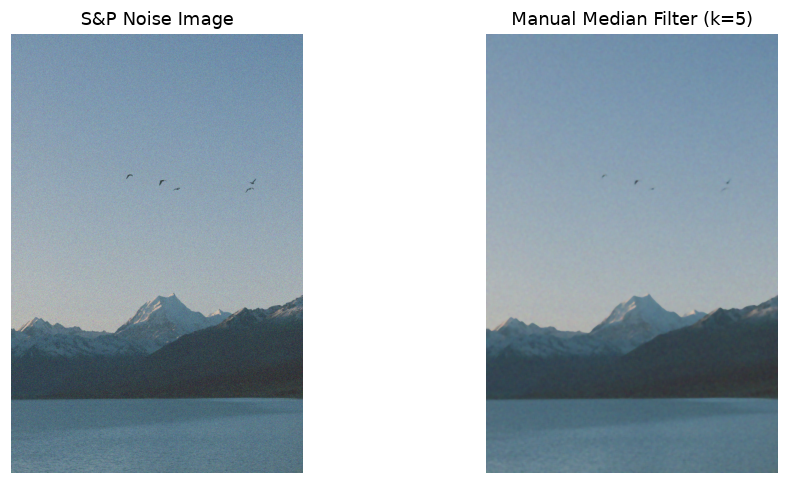

In [8]:
def manual_median_filter_color(image, kernel_size=5):
    """
    手动实现彩色图像的中值滤波
    :param image: 输入彩色图像 (H, W, 3)，uint8
    :param kernel_size: 滤波窗口大小（必须为奇数）
    :return: 滤波后的彩色图像
    """
    assert kernel_size % 2 == 1, 'kernel_size 必须是奇数'
    pad = kernel_size // 2
    out = np.zeros_like(image)

    for c in range(image.shape[2]):                  # 逐通道处理
        channel = image[:, :, c]
        padded = np.pad(channel, pad, mode='edge')   # 边缘填充，避免越界
        windows = np.lib.stride_tricks.sliding_window_view(
            padded, (kernel_size, kernel_size))      # shape: (H, W, k, k)
        out[:, :, c] = np.median(windows, axis=(-2, -1))

    return out


# 为控制内存与运行时间，先把图缩放到最长边 800 像素，再手动滤波
max_side = 800
h, w = sp_u8.shape[:2]
scale = min(1.0, max_side / max(h, w))
if scale < 1.0:
    small = cv2.resize(sp_u8, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
else:
    small = sp_u8
print('手动滤波使用尺寸:', small.shape)

cv_mid = cv2.medianBlur(small, 5)   # 同尺寸的 OpenCV 中值滤波结果，用于对比

manual_mid = manual_median_filter_color(small, 5)
print('手动中值滤波完成，输出形状:', manual_mid.shape)

plt.figure(figsize=(10, 4.5))

plt.subplot(1, 2, 1)
plt.imshow(small)
plt.title('S&P Noise Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(manual_mid)
plt.title('Manual Median Filter (k=5)')
plt.axis('off')

plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/manual_median.jpg', dpi=300, bbox_inches='tight')
plt.show()


In [9]:
# 与 OpenCV 内置中值滤波对比，验证手动实现是否正确（同尺寸）
diff = np.abs(manual_mid.astype(np.int16) - cv_mid.astype(np.int16))
print('手动中值滤波 vs cv2.medianBlur')
print('  最大差异:', diff.max())
print('  平均差异:', round(float(diff.mean()), 3))


手动中值滤波 vs cv2.medianBlur
  最大差异: 0
  平均差异: 0.0


## 7. 实验结论

1. **色彩空间**：`cv2.imread` 读入为 BGR，Matplotlib 按 RGB 显示，直接显示会红蓝互换，需要 `cv2.COLOR_BGR2RGB` 转换。
2. **椒盐噪声**：局部突变、稀疏的黑白 / 彩色噪点，**中值滤波**去噪效果最好，且能保留边缘。
3. **高斯噪声**：全局连续的小幅随机偏差，**均值滤波 / 高斯滤波**平滑效果更好，但会损失部分细节。
4. **手动中值滤波**：与 `cv2.medianBlur` 结果基本一致，说明必须对 R、G、B 三个通道分别滤波。
